# 05. Category Purchase Propensity EDA

## Mục tiêu

> Chọn một `COMMODITY_DESC` đủ phù hợp cho bài toán **repeat purchase propensity** và kiểm tra giả định prediction horizon `H = 14` ngày, observation window `T = 90` ngày.

Notebook trả lời năm câu hỏi:

1. Ngành hàng nào có đủ giao dịch, household và lịch sử mua lặp lại?
2. Positive rate thay đổi thế nào với `H ∈ {7, 14, 30}` trên nhiều cutoff hợp lệ?
3. Khoảng cách giữa các lần mua của từng ngành hàng là bao lâu?
4. Bao nhiêu household mua lặp lại?
5. Hành vi mua có gắn với giảm giá/coupon không?

`DAY` là ordinal day 1–711, không phải ngày lịch. Mọi target đều tuân thủ `(cutoff, cutoff + H]` để tránh leakage.

In [1]:
%load_ext autoreload
%autoreload 2

import os
from pathlib import Path

os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

from propensity.io import scan_csv
from propensity.schema.dunnhumby import TRANSACTION_SCHEMA_OVERRIDES

pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_cols(20)
plt.rcParams.update({"figure.dpi": 110, "font.family": ["Arial", "DejaVu Sans"]})

## 1. Thiết lập business assumptions

Các cutoff cách nhau 14 ngày để mô phỏng chu kỳ chiến dịch. Cùng một common cutoff set được dùng cho cả ba horizon, nên `H = 30` quyết định cutoff cuối cùng hợp lệ.

In [2]:
project_root = Path.cwd().resolve()
if project_root.name == "notebooks":
    project_root = project_root.parent

data_dir = project_root / "data" / "raw" / "Dunnhumby"
artifact_dir = project_root / "output" / "05_category_propensity"
artifact_dir.mkdir(parents=True, exist_ok=True)

HORIZONS = (7, 14, 30)
OBSERVATION_DAYS = 90
CUTOFF_STEP_DAYS = 14
N_CANDIDATES = 10
CATEGORY_COL = "COMMODITY_DESC"
PROMO_COLS = ("RETAIL_DISC", "COUPON_DISC", "COUPON_MATCH_DISC")

## 2. Join transaction × product và kiểm tra phạm vi

Chỉ giữ giao dịch map được sang một commodity hợp lệ. `is_promo_line` bằng true nếu ít nhất một discount column âm; đây là tín hiệu mô tả, chưa phải causal treatment.

In [3]:
transactions = scan_csv(
    data_dir / "transaction_data.csv",
    schema_overrides=TRANSACTION_SCHEMA_OVERRIDES,
).select(
    "household_key", "BASKET_ID", "DAY", "PRODUCT_ID",
    "SALES_VALUE", *PROMO_COLS,
)
products = scan_csv(data_dir / "product.csv").select(
    "PRODUCT_ID", "DEPARTMENT", CATEGORY_COL, "SUB_COMMODITY_DESC"
)

purchase_lines = (
    transactions.join(products, on="PRODUCT_ID", how="inner")
    .filter(
        pl.col(CATEGORY_COL).is_not_null()
        & (pl.col(CATEGORY_COL).str.strip_chars() != "")
        & (pl.col(CATEGORY_COL) != "NO COMMODITY DESCRIPTION")
    )
    .with_columns(
        pl.any_horizontal(pl.col(column) < 0 for column in PROMO_COLS)
        .fill_null(False)
        .alias("is_promo_line")
    )
)

coverage = purchase_lines.select(
    pl.len().alias("n_lines"),
    pl.col("household_key").n_unique().alias("n_households"),
    pl.col("BASKET_ID").n_unique().alias("n_baskets"),
    pl.col(CATEGORY_COL).n_unique().alias("n_commodities"),
    pl.col("DAY").min().alias("min_day"),
    pl.col("DAY").max().alias("max_day"),
).collect()
coverage

n_lines,n_households,n_baskets,n_commodities,min_day,max_day
u32,u32,u32,u32,i64,i64
2585542,2500,276125,306,1,711


## 3. Sàng lọc 10 ngành hàng repeat-ready

Xếp hạng chính theo số household có ít nhất hai active purchase days, sau đó mới dùng coverage và basket volume để phá hòa. Cách này phù hợp hơn xếp hạng thuần doanh số cho bài toán repeat purchase.

In [4]:
household_category = (
    purchase_lines.group_by(CATEGORY_COL, "household_key")
    .agg(
        pl.col("DAY").n_unique().alias("n_purchase_days"),
        pl.col("BASKET_ID").n_unique().alias("n_baskets"),
        pl.col("SALES_VALUE").sum().alias("sales_value"),
    )
)

category_scale = (
    purchase_lines.group_by(CATEGORY_COL)
    .agg(
        pl.len().alias("n_lines"),
        pl.col("BASKET_ID").n_unique().alias("n_baskets"),
        pl.col("household_key").n_unique().alias("n_households"),
        pl.col("DAY").n_unique().alias("n_active_days"),
        pl.col("SALES_VALUE").sum().alias("sales_value"),
    )
    .join(
        household_category.group_by(CATEGORY_COL).agg(
            (pl.col("n_purchase_days") >= 2).sum().alias("n_repeat_households"),
            pl.col("n_purchase_days").median().alias("median_purchase_days"),
        ),
        on=CATEGORY_COL,
    )
    .with_columns(
        (pl.col("n_repeat_households") / pl.col("n_households"))
        .alias("repeat_household_rate")
    )
    .sort(["n_repeat_households", "n_households", "n_baskets"], descending=True)
    .collect()
)

candidates = category_scale.head(N_CANDIDATES)
candidate_names = candidates[CATEGORY_COL].to_list()
candidates

COMMODITY_DESC,n_lines,n_baskets,n_households,n_active_days,sales_value,n_repeat_households,median_purchase_days,repeat_household_rate
str,u32,u32,u32,u32,f64,u32,f64,f64
"""SOFT DRINKS""",117532,71699,2405,709,327647.3,2314,17.0,0.962162
"""FLUID MILK PRODUCTS""",85630,69278,2421,709,205356.05,2313,19.0,0.95539
"""BAKED BREAD/BUNS/ROLLS""",83232,60311,2400,709,145930.85,2294,17.0,0.955833
"""CHEESE""",74885,46898,2350,709,189528.18,2220,13.0,0.944681
"""BAG SNACKS""",67190,42037,2348,709,148375.16,2190,11.0,0.932709
"""BEEF""",48726,36733,2238,709,312103.22,2030,11.0,0.90706
"""EGGS""",28420,27886,2231,709,39995.62,2016,8.0,0.903631
"""SOUP""",46135,23594,2195,709,87799.94,1929,7.0,0.878815
"""CRACKERS/MISC BKD FD""",29723,22722,2193,708,64528.56,1916,7.0,0.873689


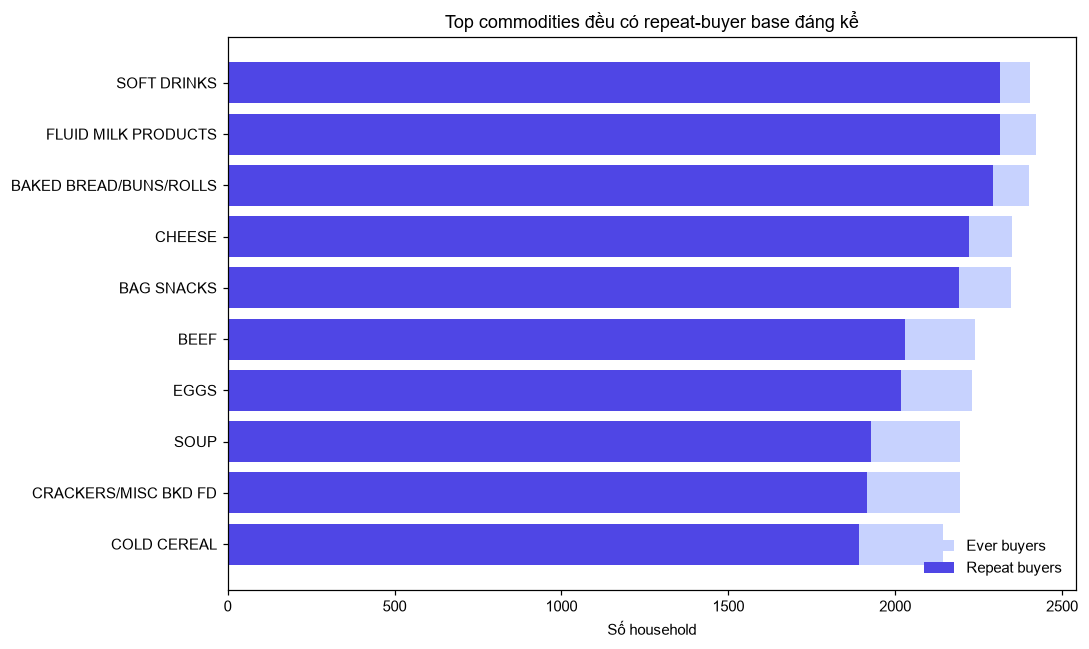

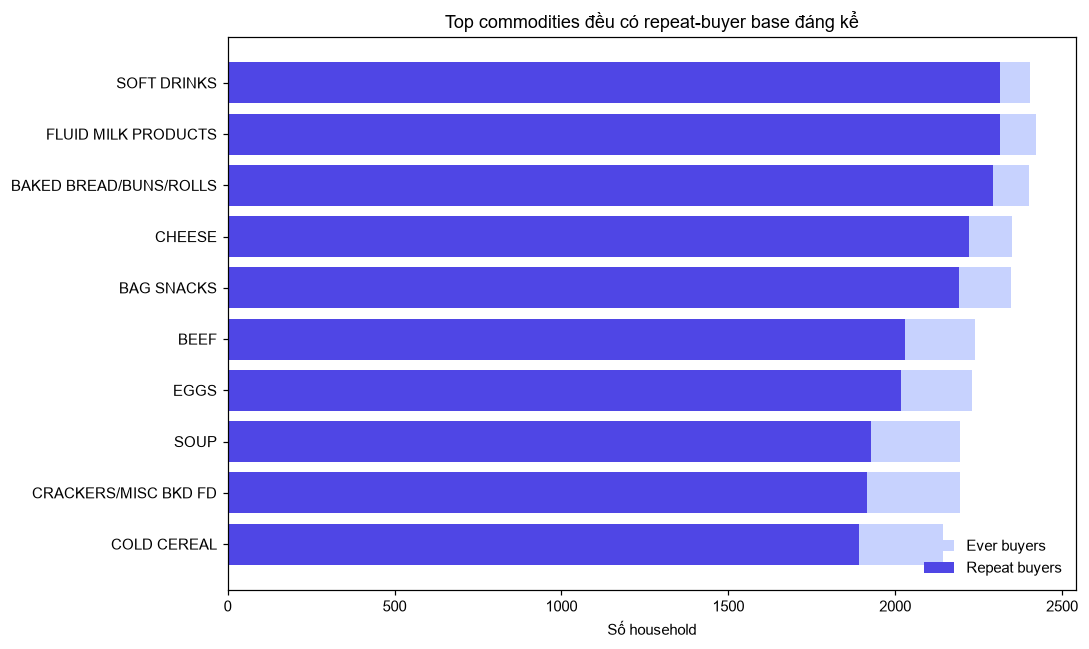

In [5]:
plot_candidates = candidates.sort("n_repeat_households")
figure, axis = plt.subplots(figsize=(10, 6))
positions = np.arange(plot_candidates.height)
axis.barh(positions, plot_candidates["n_households"], color="#C7D2FE", label="Ever buyers")
axis.barh(positions, plot_candidates["n_repeat_households"], color="#4F46E5", label="Repeat buyers")
axis.set_yticks(positions, plot_candidates[CATEGORY_COL])
axis.set_xlabel("Số household")
axis.set_title("Top commodities đều có repeat-buyer base đáng kể")
axis.legend(frameon=False)
figure.tight_layout()
figure.savefig(artifact_dir / "candidate_scale.png", dpi=150, bbox_inches="tight")
figure

## 4. Purchase cadence và repeat depth

Gap là chênh lệch giữa hai active purchase days liên tiếp của cùng household trong cùng commodity. Nhiều basket trong một ngày chỉ tạo một event để không sinh gap bằng 0.

In [6]:
category_daily = (
    purchase_lines.filter(pl.col(CATEGORY_COL).is_in(candidate_names))
    .group_by(CATEGORY_COL, "household_key", "DAY")
    .agg(
        pl.col("BASKET_ID").n_unique().alias("n_baskets"),
        pl.col("SALES_VALUE").sum().alias("sales_value"),
        pl.col("is_promo_line").any().alias("is_promo_day"),
    )
    .collect()
)

purchase_gaps = (
    category_daily.sort([CATEGORY_COL, "household_key", "DAY"])
    .with_columns(
        pl.col("DAY").diff().over(CATEGORY_COL, "household_key").alias("gap_days")
    )
    .filter(pl.col("gap_days").is_not_null())
)

gap_summary = (
    purchase_gaps.group_by(CATEGORY_COL)
    .agg(
        pl.len().alias("n_repeat_intervals"),
        pl.col("gap_days").median().alias("median_gap_days"),
        pl.col("gap_days").quantile(0.75).alias("p75_gap_days"),
        pl.col("gap_days").quantile(0.90).alias("p90_gap_days"),
        (pl.col("gap_days") <= 14).mean().alias("share_repeats_within_14d"),
        (pl.col("gap_days") <= 30).mean().alias("share_repeats_within_30d"),
    )
    .join(candidates.select(CATEGORY_COL, "repeat_household_rate"), on=CATEGORY_COL)
    .sort("median_gap_days")
)
gap_summary

COMMODITY_DESC,n_repeat_intervals,median_gap_days,p75_gap_days,p90_gap_days,share_repeats_within_14d,share_repeats_within_30d,repeat_household_rate
str,u32,f64,f64,f64,f64,f64,f64
"""SOFT DRINKS""",65705,7.0,18.0,41.0,0.704178,0.858976,0.962162
"""FLUID MILK PRODUCTS""",65345,9.0,18.0,39.0,0.681368,0.865085,0.95539
"""BAKED BREAD/BUNS/ROLLS""",56894,10.0,21.0,44.0,0.63483,0.838893,0.955833
"""CHEESE""",43767,13.0,27.0,57.0,0.556264,0.784861,0.944681
"""BAG SNACKS""",38778,13.0,28.0,63.0,0.553819,0.769483,0.932709
"""BEEF""",34044,14.0,29.0,66.0,0.527083,0.759958,0.90706
"""COLD CEREAL""",22721,18.0,39.0,87.0,0.427842,0.681572,0.883754
"""SOUP""",21113,19.0,43.0,99.0,0.412637,0.652915,0.878815
"""EGGS""",25396,20.0,40.0,83.0,0.394826,0.670106,0.903631


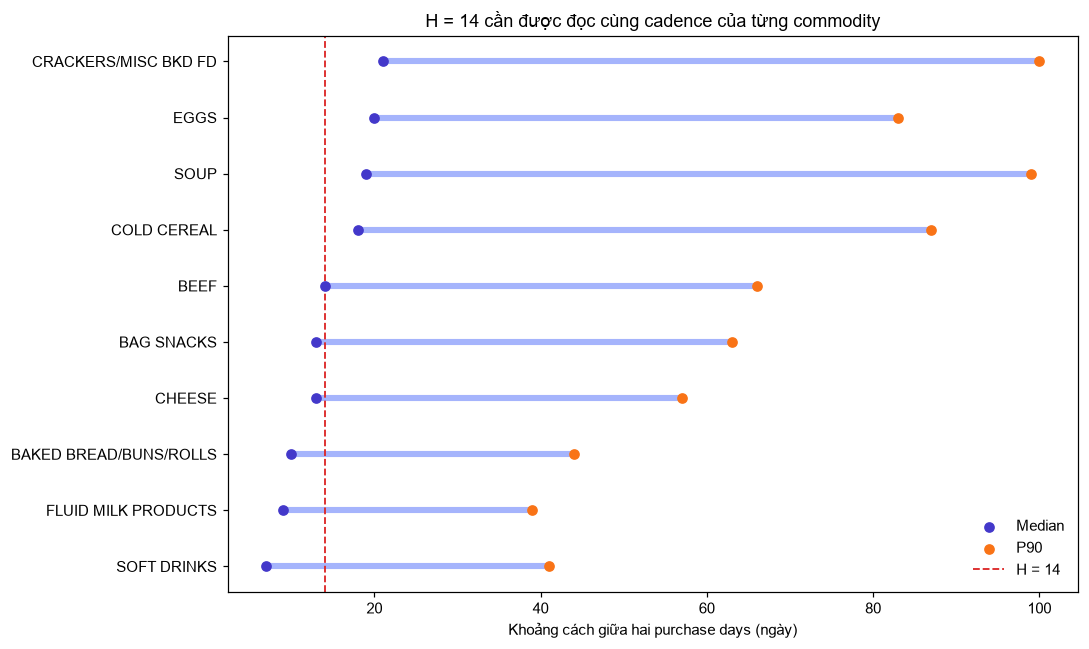

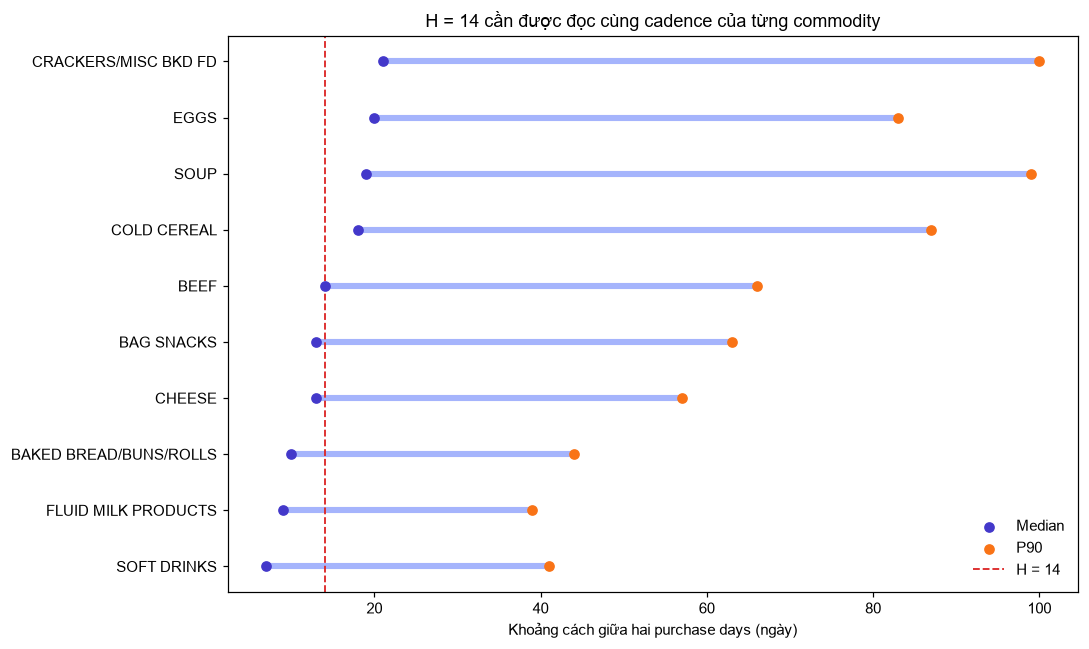

In [7]:
figure, axis = plt.subplots(figsize=(10, 6))
positions = np.arange(gap_summary.height)
axis.hlines(positions, gap_summary["median_gap_days"], gap_summary["p90_gap_days"], color="#A5B4FC", linewidth=4)
axis.scatter(gap_summary["median_gap_days"], positions, color="#4338CA", label="Median", zorder=3)
axis.scatter(gap_summary["p90_gap_days"], positions, color="#F97316", label="P90", zorder=3)
axis.axvline(14, color="#DC2626", linestyle="--", linewidth=1.2, label="H = 14")
axis.set_yticks(positions, gap_summary[CATEGORY_COL])
axis.set_xlabel("Khoảng cách giữa hai purchase days (ngày)")
axis.set_title("H = 14 cần được đọc cùng cadence của từng commodity")
axis.legend(frameon=False)
figure.tight_layout()
figure.savefig(artifact_dir / "category_purchase_gaps.png", dpi=150, bbox_inches="tight")
figure

## 5. Target rate ở H = 7/14/30 trên common cutoffs

Mỗi row của panel là `(household, commodity, cutoff)`.

- `all_household_positive_rate`: xác suất mua trong toàn bộ 2.500 household — gần với category adoption + repeat trộn chung.
- `repeat_positive_rate`: xác suất mua trong các household đã từng mua commodity trước hoặc đúng cutoff.
- `active_90d_positive_rate`: xác suất mua trong prior buyers có ít nhất một purchase day thuộc 90 ngày gần cutoff — cohort phù hợp với `T = 90`.

In [8]:
min_day = int(coverage["min_day"][0])
max_day = int(coverage["max_day"][0])
cutoff_values = list(range(
    min_day + OBSERVATION_DAYS - 1,
    max_day - max(HORIZONS) + 1,
    CUTOFF_STEP_DAYS,
))
households = purchase_lines.select("household_key").unique().collect()
cutoffs = pl.DataFrame({"cutoff_day": cutoff_values})
purchase_days = category_daily.select(CATEGORY_COL, "household_key", "DAY").sort(
    [CATEGORY_COL, "household_key", "DAY"]
)

horizon_tables = []
for category in candidate_names:
    category_events = purchase_days.filter(pl.col(CATEGORY_COL) == category).drop(CATEGORY_COL)
    category_panel = (
        households.join(cutoffs, how="cross")
        .with_columns((pl.col("cutoff_day") + 1).alias("future_start_day"))
        .sort(["household_key", "cutoff_day"])
        .join_asof(
            category_events.rename({"DAY": "last_purchase_day"}),
            left_on="cutoff_day",
            right_on="last_purchase_day",
            by="household_key",
            strategy="backward",
        )
        .join_asof(
            category_events.rename({"DAY": "next_purchase_day"}),
            left_on="future_start_day",
            right_on="next_purchase_day",
            by="household_key",
            strategy="forward",
        )
        .with_columns(
            pl.col("last_purchase_day").is_not_null().alias("is_prior_buyer"),
            (pl.col("last_purchase_day") > pl.col("cutoff_day") - OBSERVATION_DAYS)
            .fill_null(False)
            .alias("is_active_90d_buyer"),
        )
    )
    for horizon in HORIZONS:
        target = (
            pl.col("next_purchase_day") <= pl.col("cutoff_day") + horizon
        ).fill_null(False)
        horizon_tables.append(
            category_panel.group_by("cutoff_day").agg(
                pl.lit(category).first().alias(CATEGORY_COL),
                pl.lit(horizon).first().alias("horizon_days"),
                pl.len().alias("n_households"),
                pl.col("is_prior_buyer").sum().alias("n_prior_buyers"),
                pl.col("is_active_90d_buyer").sum().alias("n_active_90d_buyers"),
                target.sum().alias("n_positive_all"),
                (target & pl.col("is_prior_buyer")).sum().alias("n_positive_repeat"),
                (target & pl.col("is_active_90d_buyer")).sum().alias("n_positive_active_90d"),
            )
        )

target_by_cutoff = (
    pl.concat(horizon_tables)
    .with_columns(
        (pl.col("n_positive_all") / pl.col("n_households")).alias("all_household_positive_rate"),
        (pl.col("n_positive_repeat") / pl.col("n_prior_buyers")).alias("repeat_positive_rate"),
        (pl.col("n_positive_active_90d") / pl.col("n_active_90d_buyers")).alias("active_90d_positive_rate"),
    )
)

target_summary = (
    target_by_cutoff.group_by(CATEGORY_COL, "horizon_days")
    .agg(
        pl.len().alias("n_cutoffs"),
        pl.col("n_prior_buyers").median().alias("median_prior_buyers"),
        pl.col("n_active_90d_buyers").median().alias("median_active_90d_buyers"),
        pl.col("all_household_positive_rate").median().alias("median_all_positive_rate"),
        pl.col("repeat_positive_rate").median().alias("median_repeat_positive_rate"),
        pl.col("repeat_positive_rate").quantile(0.10).alias("p10_repeat_positive_rate"),
        pl.col("repeat_positive_rate").quantile(0.90).alias("p90_repeat_positive_rate"),
        pl.col("active_90d_positive_rate").median().alias("median_active_90d_positive_rate"),
    )
    .sort([CATEGORY_COL, "horizon_days"])
)
target_summary

C:\Users\manhh\AppData\Local\Temp\ipykernel_35664\1673842335.py:21: UserWarning: Sortedness of columns cannot be checked when 'by' groups provided
  .join_asof(
C:\Users\manhh\AppData\Local\Temp\ipykernel_35664\1673842335.py:28: UserWarning: Sortedness of columns cannot be checked when 'by' groups provided
  .join_asof(


COMMODITY_DESC,horizon_days,n_cutoffs,median_prior_buyers,median_active_90d_buyers,median_all_positive_rate,median_repeat_positive_rate,p10_repeat_positive_rate,p90_repeat_positive_rate,median_active_90d_positive_rate
str,i32,u32,f64,f64,f64,f64,f64,f64,f64
"""BAG SNACKS""",7,43,2164.0,1547.0,0.1516,0.175334,0.159448,0.210414,0.222008
"""BAG SNACKS""",14,43,2164.0,1547.0,0.2556,0.294894,0.269871,0.33121,0.365049
"""BAG SNACKS""",30,43,2164.0,1547.0,0.396,0.454545,0.422492,0.499086,0.548367
"""BAKED BREAD/BUNS/ROLLS""",7,43,2283.0,1762.0,0.2188,0.244257,0.220681,0.273904,0.293036
"""BAKED BREAD/BUNS/ROLLS""",14,43,2283.0,1762.0,0.3516,0.381385,0.365905,0.434177,0.460724
"""BAKED BREAD/BUNS/ROLLS""",30,43,2283.0,1762.0,0.5052,0.546312,0.529312,0.592669,0.644172
"""BEEF""",7,43,2017.0,1430.0,0.1416,0.17536,0.148524,0.199686,0.221306
"""BEEF""",14,43,2017.0,1430.0,0.2324,0.290537,0.26057,0.331847,0.363699
"""BEEF""",30,43,2017.0,1430.0,0.3652,0.449209,0.417557,0.505023,0.547222


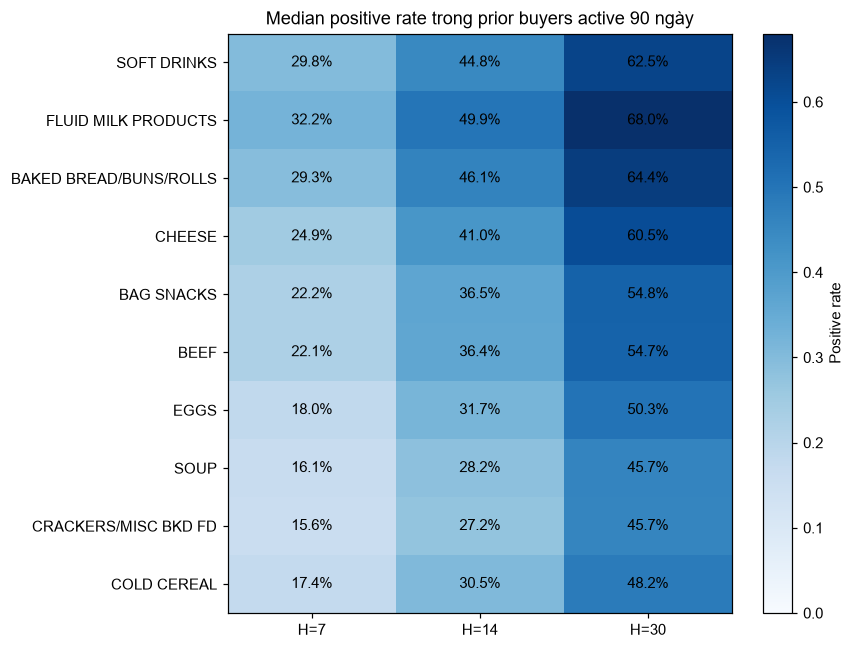

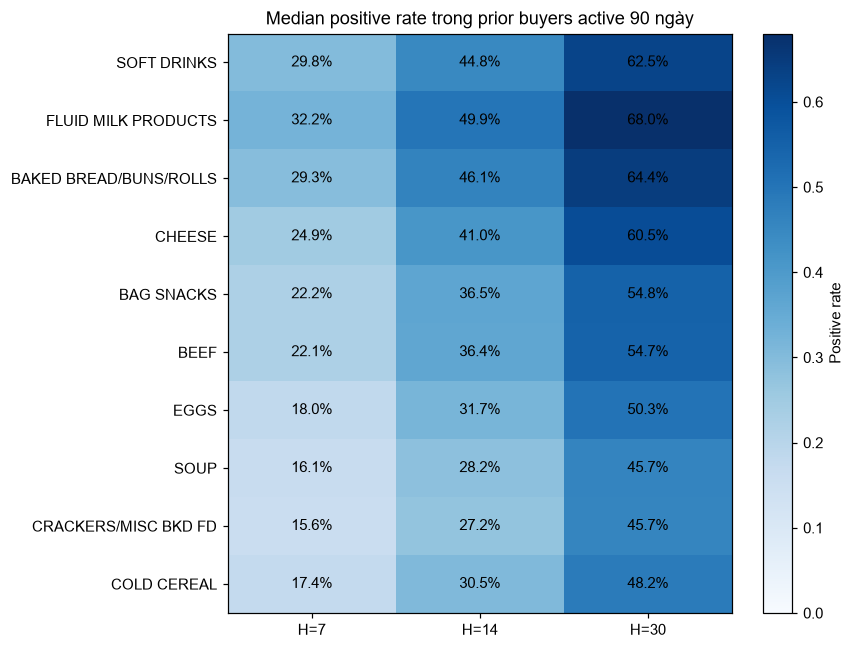

In [9]:
heatmap = (
    target_summary.select(CATEGORY_COL, "horizon_days", "median_active_90d_positive_rate")
    .pivot(on="horizon_days", index=CATEGORY_COL, values="median_active_90d_positive_rate")
    .join(candidates.select(CATEGORY_COL, "n_repeat_households"), on=CATEGORY_COL)
    .sort("n_repeat_households", descending=True)
)
heat_values = heatmap.select([str(horizon) for horizon in HORIZONS]).to_numpy()
figure, axis = plt.subplots(figsize=(8, 6))
image = axis.imshow(heat_values, cmap="Blues", aspect="auto", vmin=0)
axis.set_xticks(np.arange(len(HORIZONS)), [f"H={horizon}" for horizon in HORIZONS])
axis.set_yticks(np.arange(heatmap.height), heatmap[CATEGORY_COL])
for row in range(heat_values.shape[0]):
    for column in range(heat_values.shape[1]):
        axis.text(column, row, f"{heat_values[row, column]:.1%}", ha="center", va="center")
axis.set_title("Median positive rate trong prior buyers active 90 ngày")
figure.colorbar(image, ax=axis, label="Positive rate")
figure.tight_layout()
figure.savefig(artifact_dir / "horizon_positive_rate.png", dpi=150, bbox_inches="tight")
figure

## 6. Promotion dependency

`promo_purchase_day_rate` mô tả tỷ trọng purchase days có ít nhất một line giảm giá/coupon. Chỉ số này không chứng minh coupon làm tăng mua; nó giúp đánh giá ngành hàng có phù hợp với marketing scenario và cần kiểm soát treatment leakage hay không.

In [10]:
promo_households = (
    category_daily.group_by(CATEGORY_COL, "household_key")
    .agg(
        pl.col("is_promo_day").any().alias("ever_promo"),
        (~pl.col("is_promo_day")).any().alias("ever_non_promo"),
    )
)
promo_summary = (
    category_daily.group_by(CATEGORY_COL)
    .agg(
        pl.len().alias("n_purchase_days"),
        pl.col("is_promo_day").mean().alias("promo_purchase_day_rate"),
        pl.col("sales_value").filter(pl.col("is_promo_day")).sum().alias("promo_day_sales"),
        pl.col("sales_value").sum().alias("total_sales"),
    )
    .join(
        promo_households.group_by(CATEGORY_COL).agg(
            pl.col("ever_promo").mean().alias("share_buyers_ever_promo"),
            (pl.col("ever_promo") & pl.col("ever_non_promo")).mean().alias("share_buyers_mixed_context"),
        ),
        on=CATEGORY_COL,
    )
    .with_columns((pl.col("promo_day_sales") / pl.col("total_sales")).alias("promo_day_sales_share"))
    .sort("promo_purchase_day_rate", descending=True)
)
promo_summary

COMMODITY_DESC,n_purchase_days,promo_purchase_day_rate,promo_day_sales,total_sales,share_buyers_ever_promo,share_buyers_mixed_context,promo_day_sales_share
str,u32,f64,f64,f64,f64,f64,f64
"""CHEESE""",46117,0.83891,162140.22,189528.18,0.984681,0.754468,0.855494
"""BAKED BREAD/BUNS/ROLLS""",59294,0.775627,112407.86,145930.85,0.979583,0.837917,0.770282
"""COLD CEREAL""",24863,0.69529,82065.47,111702.42,0.928571,0.70915,0.734679
"""SOFT DRINKS""",68110,0.685244,251713.57,327647.3,0.975884,0.849064,0.768246
"""CRACKERS/MISC BKD FD""",22521,0.673327,43343.38,64528.56,0.936161,0.711354,0.671693
"""BAG SNACKS""",41126,0.582405,97808.29,148375.16,0.9523,0.84753,0.659196
"""BEEF""",36282,0.541508,188873.48,312103.22,0.898123,0.810098,0.605164
"""FLUID MILK PRODUCTS""",67766,0.504383,102902.11,205356.05,0.933912,0.887237,0.501091
"""SOUP""",23308,0.486314,46577.73,87799.94,0.879271,0.764465,0.530498


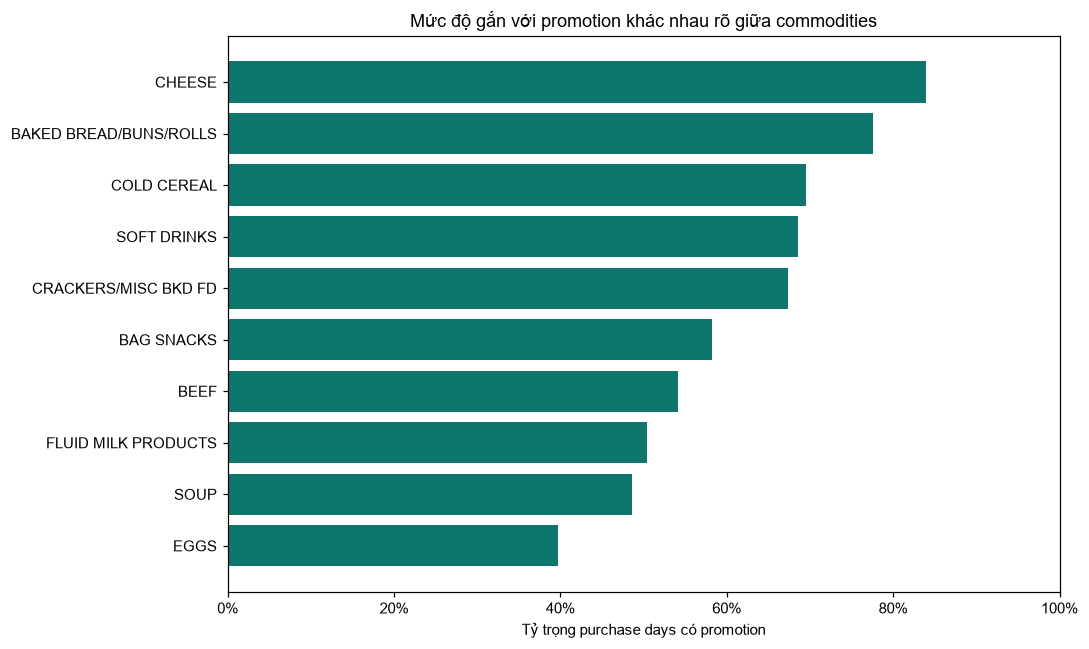

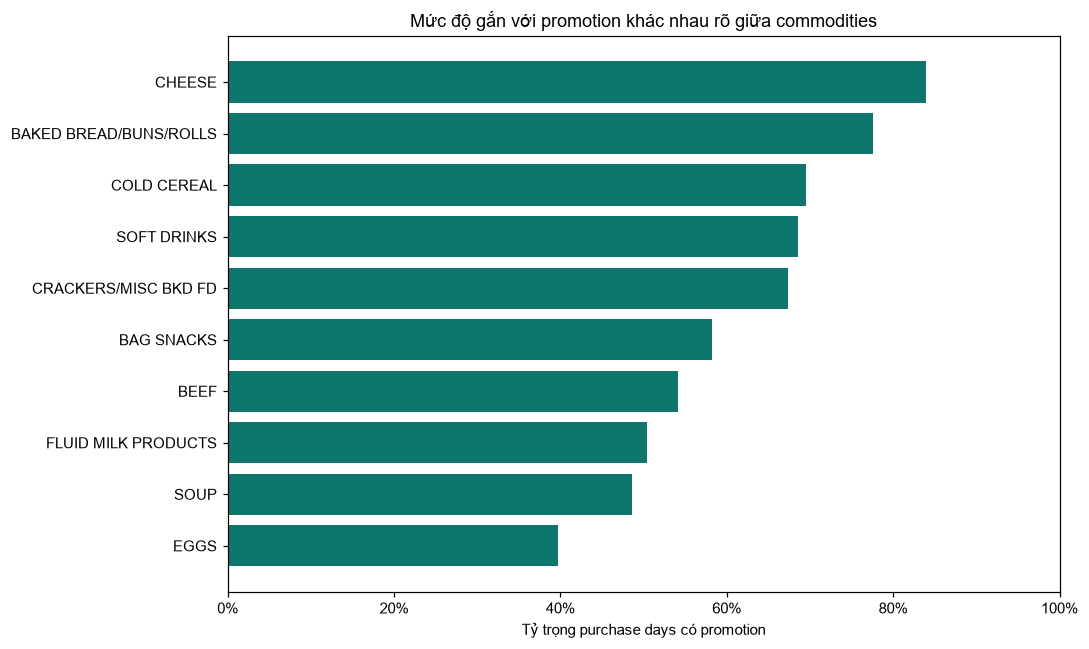

In [11]:
plot_promo = promo_summary.sort("promo_purchase_day_rate")
figure, axis = plt.subplots(figsize=(10, 6))
positions = np.arange(plot_promo.height)
axis.barh(positions, plot_promo["promo_purchase_day_rate"], color="#0F766E")
axis.set_yticks(positions, plot_promo[CATEGORY_COL])
axis.set_xlabel("Tỷ trọng purchase days có promotion")
axis.set_xlim(0, 1)
axis.set_title("Mức độ gắn với promotion khác nhau rõ giữa commodities")
axis.xaxis.set_major_formatter(lambda value, _: f"{value:.0%}")
figure.tight_layout()
figure.savefig(artifact_dir / "promotion_dependency.png", dpi=150, bbox_inches="tight")
figure

## 7. Decision table

Bảng cuối ghép bốn nhóm evidence tại `H = 14`: scale, repeat depth, cadence, positive rate và promotion context. Không dùng một composite score tùy ý; lựa chọn cuối cùng cần được bảo vệ bằng business + domain + data.

In [12]:
decision_table = (
    candidates.select(
        CATEGORY_COL, "n_households", "n_repeat_households", "repeat_household_rate",
    )
    .join(
        gap_summary.select(
            CATEGORY_COL, "median_gap_days", "p90_gap_days", "share_repeats_within_14d",
        ),
        on=CATEGORY_COL,
    )
    .join(
        target_summary.filter(pl.col("horizon_days") == 14).select(
            CATEGORY_COL, "median_prior_buyers", "median_active_90d_buyers",
            "median_repeat_positive_rate", "median_active_90d_positive_rate",
            "p10_repeat_positive_rate", "p90_repeat_positive_rate",
        ),
        on=CATEGORY_COL,
    )
    .join(
        promo_summary.select(
            CATEGORY_COL, "promo_purchase_day_rate", "share_buyers_mixed_context",
        ),
        on=CATEGORY_COL,
    )
    .sort(["n_repeat_households", "median_active_90d_positive_rate"], descending=True)
)
decision_table

COMMODITY_DESC,n_households,n_repeat_households,repeat_household_rate,median_gap_days,p90_gap_days,share_repeats_within_14d,median_prior_buyers,median_active_90d_buyers,median_repeat_positive_rate,median_active_90d_positive_rate,p10_repeat_positive_rate,p90_repeat_positive_rate,promo_purchase_day_rate,share_buyers_mixed_context
str,u32,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""SOFT DRINKS""",2405,2314,0.962162,7.0,41.0,0.704178,2281.0,1756.0,0.378366,0.448335,0.349597,0.428127,0.685244,0.849064
"""FLUID MILK PRODUCTS""",2421,2313,0.95539,9.0,39.0,0.681368,2301.0,1805.0,0.419314,0.499449,0.395151,0.45542,0.504383,0.887237
"""BAKED BREAD/BUNS/ROLLS""",2400,2294,0.955833,10.0,44.0,0.63483,2283.0,1762.0,0.381385,0.460724,0.365905,0.434177,0.775627,0.837917
"""CHEESE""",2350,2220,0.944681,13.0,57.0,0.556264,2186.0,1634.0,0.33287,0.410116,0.313786,0.364353,0.83891,0.754468
"""BAG SNACKS""",2348,2190,0.932709,13.0,63.0,0.553819,2164.0,1547.0,0.294894,0.365049,0.269871,0.33121,0.582405,0.84753
"""BEEF""",2238,2030,0.90706,14.0,66.0,0.527083,2017.0,1430.0,0.290537,0.363699,0.26057,0.331847,0.541508,0.810098
"""EGGS""",2231,2016,0.903631,20.0,83.0,0.394826,2011.0,1354.0,0.250694,0.317091,0.220162,0.28882,0.397256,0.776782
"""SOUP""",2195,1929,0.878815,19.0,99.0,0.412637,1911.0,1187.0,0.224742,0.281792,0.158209,0.272446,0.486314,0.764465
"""CRACKERS/MISC BKD FD""",2193,1916,0.873689,21.0,100.0,0.371901,1915.0,1226.0,0.209238,0.272446,0.189979,0.250702,0.673327,0.711354


## 8. Kết luận từ lần chạy hiện tại

**Đề xuất chọn `CHEESE` làm commodity đầu tiên cho category repeat purchase propensity với `H = 14`, `T = 90`.**

- Data scale: 2.350 buyers, trong đó 2.220 household mua ở ít nhất hai active days; median cutoff có 1.634 prior buyers active trong 90 ngày.
- Domain/cadence: median purchase gap là 13 ngày, sát chu kỳ campaign 14 ngày; 55,6% repeat intervals nằm trong 14 ngày.
- Target: median positive rate tại H=14 là 33,3% trên toàn prior-buyer cohort và 41,0% trên prior buyers active 90 ngày; P10–P90 của repeat rate là 31,4%–36,4%, chưa quá hiếm hoặc bão hòa.
- Business fit: 83,9% purchase days có promotion, cao nhất trong 10 candidates. Đây là evidence mô tả cho campaign relevance, không phải causal lift.

`FLUID MILK PRODUCTS` là sensitivity candidate tốt cho replenishment (2.313 repeat households, median gap 9 ngày, active-90d positive rate 49,9% tại H=14), nhưng nhịp mua nhanh hơn và promotion rate 50,4% khiến nó kém sát giả định campaign 2 tuần hơn `CHEESE`.

### Cách chốt commodity sau EDA

Ưu tiên một commodity khi đồng thời thỏa các điều kiện sau:

- `n_repeat_households` đủ lớn để tạo nhiều household-cutoff samples.
- `median_active_90d_buyers` không quá nhỏ, vì đây là scoring cohort phù hợp `T = 90`.
- Positive rate tại `H = 14` không quá hiếm hoặc quá bão hòa và tương đối ổn định giữa P10–P90 cutoff.
- Median/P75 gap có quan hệ hợp lý với nhịp campaign 14 ngày.
- Promotion rate đủ đáng kể cho business scenario, nhưng không nên diễn giải là causal lift.

Sau khi chọn commodity, bước modeling cần cố định cohort, cutoff policy và feature windows trước khi train; mọi feature chỉ được dùng dữ liệu `DAY <= cutoff`. Category-agnostic propensity nên được giữ làm baseline để định lượng giá trị tăng thêm của bài toán category-specific.